# Lab 10: Odometry vs. odometry + gyro localization
Digit **32** (12 segments), program `lab10_odometry_gyro.qrs`. Run A: `course = course_odom`. Run B: `course = course + gyro_inc`.

Log line: `t, i, theta_l, theta_r, gz, gt, x, y, course` (ms, waypoint, rad, rad, mdeg/s, gyro timestamp in 256 µs, cm, cm, rad). Lines with `i = -1` are the 10 s at rest for `b0`.

In [7]:
from google.colab import files
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

files.upload()
r, B, s = 4.3, 19.6, -0.047                         # wheel radius and base in cm, gyro scale factor (Lab 9)
X_ref = np.array([0, 30, 30, 0, 30, 30, 0, 50, 80, 80, 50, 50, 80])   # start + 12 waypoints, cm
Y_ref = np.array([0, 0, 30, 30, 30, 60, 60, 60, 60, 30, 30, 0, 0])
course_ref = np.arctan2(np.diff(Y_ref), np.diff(X_ref))                # Step 1: ideal course of each segment
path_ref = np.hypot(np.diff(X_ref), np.diff(Y_ref))                    # Step 1: ideal path of each segment
wrap = lambda a: (a + np.pi) % (2 * np.pi) - np.pi                     # angle to [-pi, pi)
cols = ['t', 'i', 'theta_l', 'theta_r', 'gz', 'gt', 'x', 'y', 'course']
log = {k: pd.read_csv(f'lab10_run_{k}.txt', names=cols) for k in 'AB'}

Saving lab10_run_A.txt to lab10_run_A (1).txt
Saving lab10_run_B.txt to lab10_run_B (1).txt


## Step 4.2: offline recomputation
Both methods on both logs give 4 paths. The method each run used must reproduce the log.

In [8]:
def localize(d, gyro, s=s):                         # the robot's computation, repeated from the raw sensors
    b0 = d.gz[d.i < 0].mean()                       # mean of the 10 s at rest
    m = d[d.i >= 0]
    path = (m.theta_r + m.theta_l).values * r / 2
    if gyro:                                        # course = course + gyro_inc
        dt = m['gt'].diff().fillna(0).values * 0.000256                 # gyro timestamp, 256 us units
        course = np.cumsum((m.gz.values - b0) / 1000 / (1 + s) * dt) * np.pi / 180
    else:                                           # course = course_odom
        course = (m.theta_r - m.theta_l).values * r / B
    step = np.diff(path, prepend=0)                 # path - prev_path
    fwd = (m.theta_l.diff() > 0) & (m.theta_r.diff() > 0)               # both wheels forward: driving
    return pd.DataFrame({'t': m.t.values / 1000, 'i': m.i.values, 'path': path, 'course': course, 'fwd': fwd.values,
                         'x': np.cumsum(step * np.cos(course)), 'y': np.cumsum(step * np.sin(course))})

P = {(k, g): localize(log[k], g) for k in 'AB' for g in (False, True)}  # (run, course from gyro?)
used = {'A': False, 'B': True}
for k in 'AB':
    d = log[k]; m, p = d[d.i >= 0], P[k, used[k]]
    print(f'run {k}: {np.median(np.diff(m.t)):.0f} ms per cycle, b0 = {d.gz[d.i < 0].mean() / 1000:.3f} deg/s, '
          f'fastest turn {abs(m.gz).max() / 1000:.0f} deg/s; robot vs. offline: {np.hypot(m.x - p.x.values, m.y - p.y.values).max():.3f} cm, '
          f'{np.degrees(abs(m.course - p.course.values)).max():.4f} deg')

run A: 60 ms per cycle, b0 = 0.531 deg/s, fastest turn 91 deg/s; robot vs. offline: 0.000 cm, 0.0000 deg
run B: 60 ms per cycle, b0 = 0.440 deg/s, fastest turn 80 deg/s; robot vs. offline: 0.001 cm, 0.0004 deg


## Steps 4.1 and 4.2: trajectories
Numbers: segments 1 to 12. Solid: logged. Dashed: the same run recomputed with the other method. `measured`: end of the robot centre, taped from the start mark.

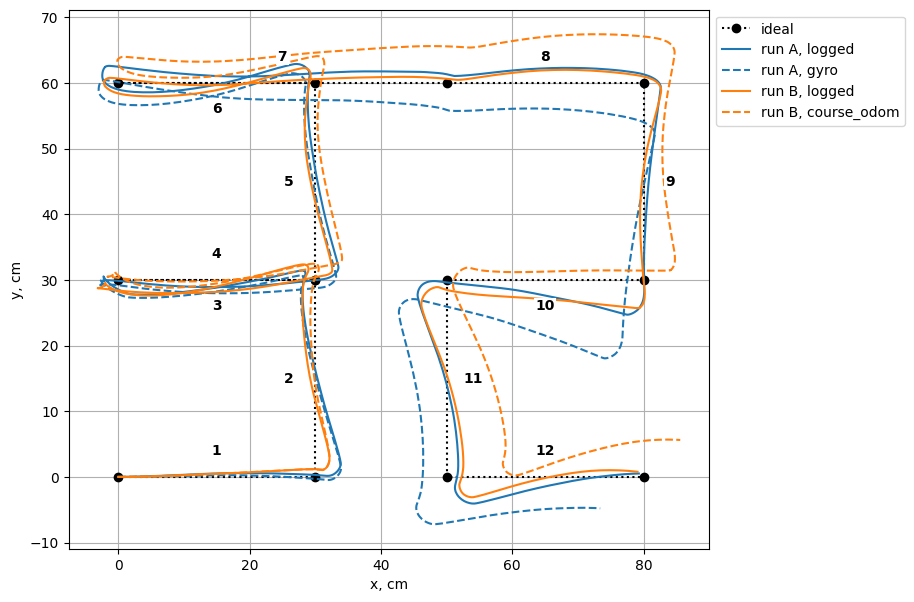

In [9]:
measured = {'A': None, 'B': None}                   # e.g. {'A': (79.0, 1.5), 'B': (80.0, 0.5)}, cm

plt.figure(figsize=(11, 7))
plt.plot(X_ref, Y_ref, 'k:o', label='ideal')
xm = (X_ref[:-1] + X_ref[1:]) / 2 - 4 * np.diff(Y_ref) / path_ref   # segment middle, 4 cm left of the travel direction
ym = (Y_ref[:-1] + Y_ref[1:]) / 2 + 4 * np.diff(X_ref) / path_ref
for j in range(12):
    plt.text(xm[j], ym[j], j + 1, ha='center', va='center', weight='bold', bbox=dict(fc='white', ec='none', pad=1))
for k, c in zip('AB', ['C0', 'C1']):
    m, other = log[k][log[k].i >= 0], P[k, not used[k]]
    plt.plot(m.x, m.y, c, label=f'run {k}, logged')
    plt.plot(other.x, other.y, c + '--', label=f"run {k}, {'course_odom' if used[k] else 'gyro'}")
    if measured[k]:
        plt.plot(*measured[k], c + '*', ms=15, label=f'run {k}, measured end')
plt.axis('scaled'); plt.grid(); plt.legend(loc='upper left', bbox_to_anchor=(1, 1)); plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.show()

## Steps 4.3 and 4.4: comparison table
`course`: mean course on the straight of the segment (the longest stretch with both wheels forward, so the turn in place is left out), deg. `path`: path travelled while heading to waypoint `i`, cm.

In [10]:
def segments(p):
    course = []
    for j in range(12):
        seg = p[p.i == j]
        run = (~seg.fwd).cumsum()[seg.fwd]          # stretches with both wheels forward
        straight = run.index[run == run.value_counts().idxmax()]       # the longest one is the straight
        course.append(course_ref[j] + wrap(seg.course[straight] - course_ref[j]).mean())
    return np.degrees(course), np.diff(p.path.groupby(p.i).last(), prepend=0)

S = {k: segments(P[k, used[k]]) for k in 'AB'}     # (course, path) of each segment
c_ref = np.degrees(course_ref)
table = pd.DataFrame({'course_ref': c_ref, 'course A': S['A'][0], 'course B': S['B'][0],
                      'd_course A': S['A'][0] - c_ref, 'd_course B': S['B'][0] - c_ref,
                      'path_ref': path_ref, 'path A': S['A'][1], 'path B': S['B'][1],
                      'd_path A': S['A'][1] - path_ref, 'd_path B': S['B'][1] - path_ref}, index=range(1, 13))
display(table.round(1))
for k in 'AB':
    e = log[k].iloc[-1]                             # last logged pose
    print(f"run {k}: mean abs(d_course) {abs(table[f'd_course {k}']).mean():.1f} deg, path {S[k][1].sum():.1f} cm "
          f"({100 * (S[k][1].sum() / path_ref.sum() - 1):+.1f} %), final position error {np.hypot(e.x - X_ref[-1], e.y - Y_ref[-1]):.1f} cm, "
          f"final course error {np.degrees(wrap(e.course - course_ref[-1])):+.1f} deg")

,course_ref,course A,course B,d_course A,d_course B,path_ref,path A,path B,d_path A,d_path B
1,0.0,0.6,2.1,0.6,2.1,30.0,29.9,29.7,-0.1,-0.3
2,90.0,101.9,100.0,11.9,10.0,30.0,33.3,31.0,3.3,1.0
3,180.0,187.5,188.9,7.5,8.9,30.0,30.4,31.9,0.4,1.9
4,0.0,-0.4,2.6,-0.4,2.6,30.0,34.4,34.0,4.4,4.0
5,90.0,99.6,97.3,9.6,7.3,30.0,33.1,31.6,3.1,1.6
6,180.0,188.2,188.4,8.2,8.4,30.0,31.7,31.9,1.7,1.9
7,0.0,-1.6,-0.1,-1.6,-0.1,50.0,57.0,55.2,7.0,5.2
8,0.0,0.7,1.3,0.7,1.3,30.0,30.5,30.5,0.5,0.5
9,-90.0,-95.0,-96.0,-5.0,-6.0,30.0,32.8,32.8,2.8,2.8
10,180.0,169.6,174.4,-10.4,-5.6,30.0,34.4,34.4,4.4,4.4


run A: mean abs(d_course) 6.6 deg, path 413.7 cm (+8.9 %), final position error 0.9 cm, final course error +1.3 deg
run B: mean abs(d_course) 6.3 deg, path 406.0 cm (+6.8 %), final position error 1.2 cm, final course error -6.2 deg


## Steps 4.3 and 4.5: course and error growth

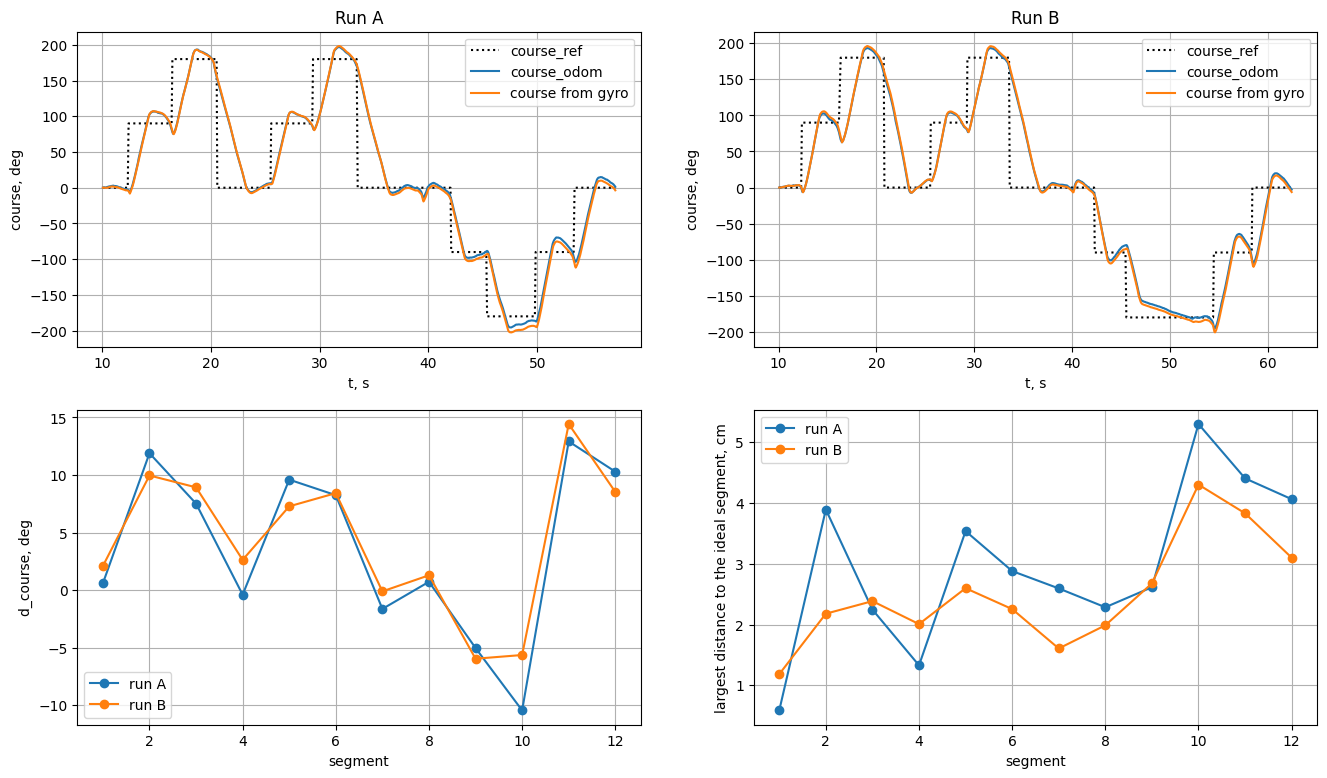

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9))
for a, k in zip(ax[0], 'AB'):
    p = P[k, used[k]]
    a.plot(p.t, np.degrees(p.course + wrap(course_ref[p.i] - p.course)), 'k:', label='course_ref')
    a.plot(p.t, np.degrees(P[k, False].course), label='course_odom')
    a.plot(p.t, np.degrees(P[k, True].course), label='course from gyro')
    a.set(title=f'Run {k}', xlabel='t, s', ylabel='course, deg')
for k in 'AB':
    p = P[k, used[k]]
    dx, dy = np.diff(X_ref)[p.i], np.diff(Y_ref)[p.i]
    off = abs(dx * (p.y - Y_ref[p.i]) - dy * (p.x - X_ref[p.i])) / np.hypot(dx, dy)   # distance to the ideal segment
    ax[1, 0].plot(range(1, 13), table[f'd_course {k}'], '-o', label=f'run {k}')
    ax[1, 1].plot(range(1, 13), off.groupby(p.i).max(), '-o', label=f'run {k}')
ax[1, 0].set(xlabel='segment', ylabel='d_course, deg')
ax[1, 1].set(xlabel='segment', ylabel='largest distance to the ideal segment, cm')
for a in ax.flat:
    a.grid(); a.legend()
plt.show()

## Error source
`B_hat` as in `Base_observer.qrs`, with the raw gyro (s = 0). In `course_odom - gyro course`: steps at the turns mean `B` or scale factor, a slope on the straights means unequal wheels, single jumps mean slip. Only the measured end separates `B` from the scale factor.

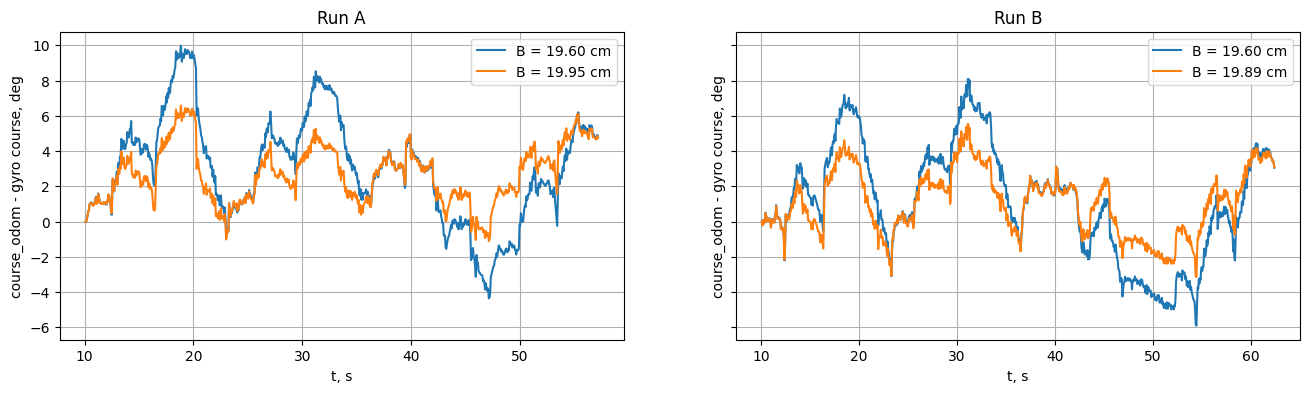

run A end: course_odom (79.3, 0.5), gyro (73.4, -4.8), gyro, s = 0 (82.9, 0.0)
run B end: course_odom (85.6, 5.6), gyro (79.1, 0.8), gyro, s = 0 (88.6, 5.6)


In [12]:
G = {k: localize(log[k], True, s=0) for k in 'AB'}  # raw gyro course
fig, ax = plt.subplots(1, 2, figsize=(16, 4), sharey=True)
for a, k in zip(ax, 'AB'):
    m = log[k][log[k].i >= 0]
    arc = np.diff((m.theta_r - m.theta_l).values, prepend=0) * r
    gyro_inc = np.diff(G[k].course, prepend=0)
    B_hat = (arc * gyro_inc).sum() / (gyro_inc ** 2).sum()
    for b in (B, B_hat):
        a.plot(G[k].t, np.degrees(np.cumsum(arc) / b - G[k].course), label=f'B = {b:.2f} cm')
    a.set(title=f'Run {k}', xlabel='t, s', ylabel='course_odom - gyro course, deg'); a.grid(); a.legend()
plt.show()
for k in 'AB':
    ends = [('course_odom', P[k, False]), ('gyro', P[k, True]), ('gyro, s = 0', G[k])]
    print(f'run {k} end: ' + ', '.join(f'{n} ({e.x.iloc[-1]:.1f}, {e.y.iloc[-1]:.1f})' for n, e in ends)
          + (f', measured {measured[k]}' if measured[k] else ''))